In [ ]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

folder = r'C:\MAT3300'
sm_file = os.path.join(folder, 'fin.nc') 

ds_sm = xr.open_dataset(sm_file)
print(ds_sm)

<xarray.Dataset> Size: 111kB
Dimensions:     (valid_time: 922, latitude: 2, longitude: 2)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2026-10-01
    expver      (valid_time) <U4 15kB ...
  * latitude    (latitude) float64 16B 40.1 40.0
  * longitude   (longitude) float64 16B -3.1 -3.0
    number      int64 8B ...
Data variables:
    src         (valid_time, latitude, longitude) float32 15kB ...
    swvl1       (valid_time, latitude, longitude) float32 15kB ...
    swvl2       (valid_time, latitude, longitude) float32 15kB ...
    swvl3       (valid_time, latitude, longitude) float32 15kB ...
    swvl4       (valid_time, latitude, longitude) float32 15kB ...
    pev         (valid_time, latitude, longitude) float32 15kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Cent

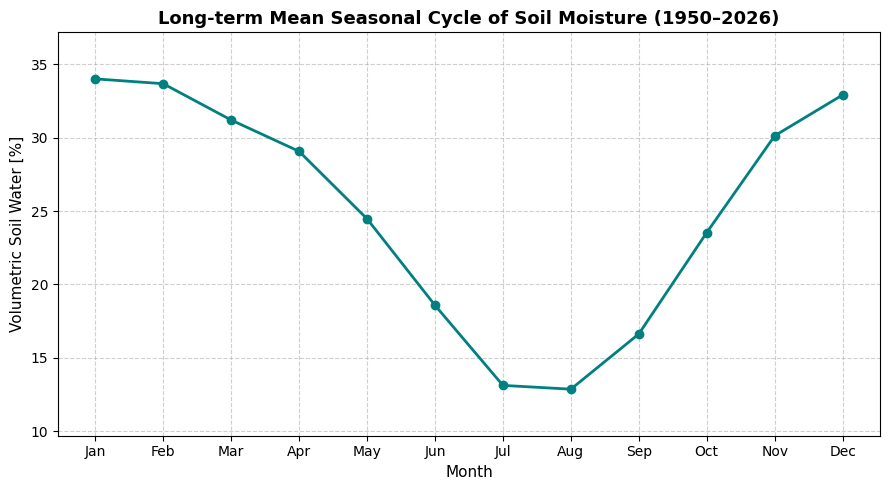

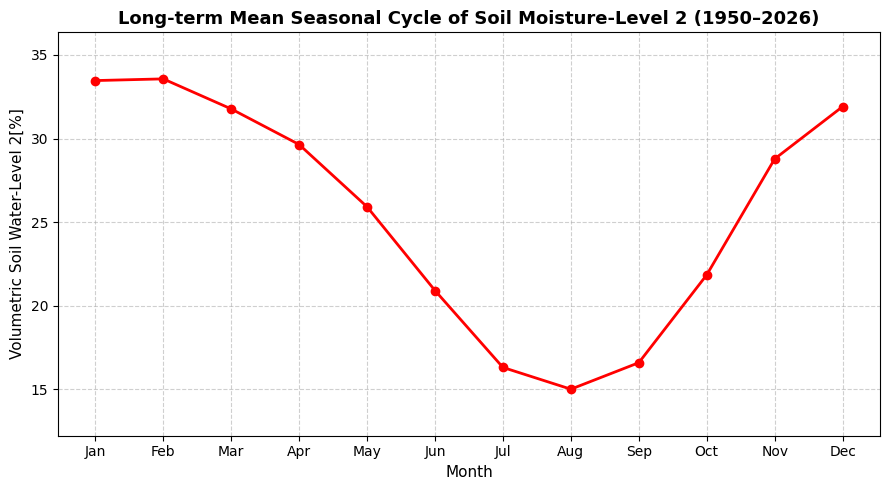

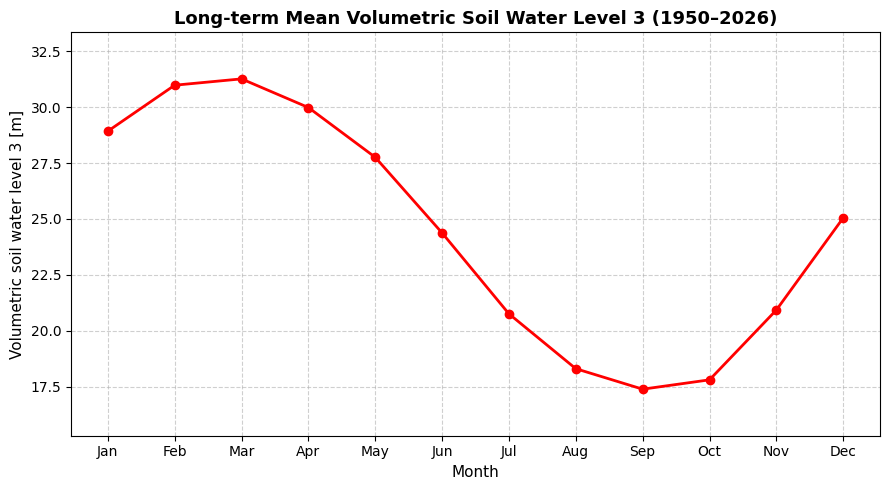

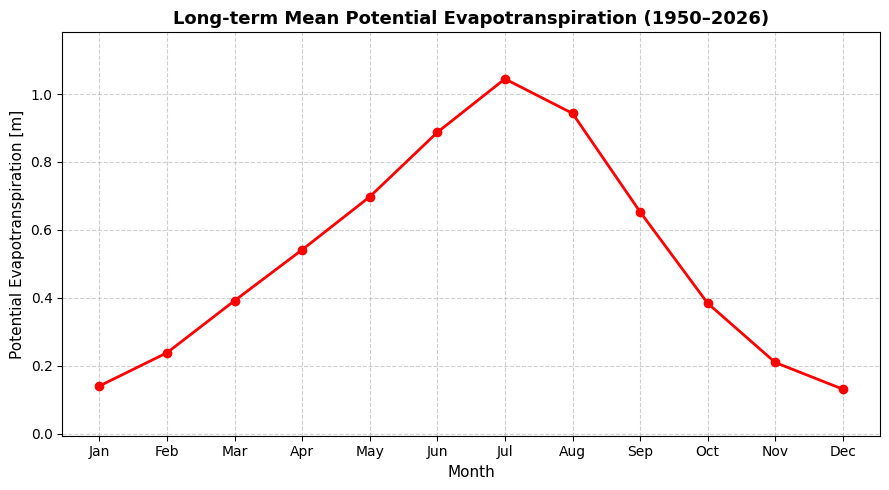

In [ ]:
import os
import xarray as xr
import matplotlib.pyplot as plt

folder = r'C:\MAT3300'
file_path = os.path.join(folder, 'fin.nc') 
ds = xr.open_dataset(file_path)
print(ds)

monthly = (
    ds["swvl1"]
    .mean(dim=["latitude", "longitude"], skipna=True)   
    .resample(valid_time="1MS")                        
    .mean()
)
monthly_pct = monthly * 100
monthly_clim = monthly_pct.groupby("valid_time.month").mean()
 
fig, ax = plt.subplots(figsize=(9, 5))
monthly_clim.plot(ax=ax, marker="o", color="teal", linewidth=2, markersize=6)

ax.set_xticks(range(1, 13))
ymin = monthly_clim.min().item()
ymax = monthly_clim.max().item()
buffer = (ymax - ymin) * 0.15  # 15% padding above and below
ax.set_ylim(ymin - buffer, ymax + buffer)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Volumetric Soil Water [%]", fontsize=11)
ax.set_title("Long-term Mean Seasonal Cycle of Soil Moisture (1950–2026)", fontsize=13, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

monthly = (
    ds["swvl2"]
    .mean(dim=["latitude", "longitude"], skipna=True)   # spatial mean only
    .resample(valid_time="1MS")                         # monthly means
    .mean()
)
monthly_pct = monthly * 100
monthly_clim = monthly_pct.groupby("valid_time.month").mean()

fig, ax = plt.subplots(figsize=(9, 5))
monthly_clim.plot(ax=ax, marker="o", color="red", linewidth=2, markersize=6)

ax.set_xticks(range(1, 13))
ymin = min(monthly_clim.min().item(), monthly_clim.min().item())
ymax = max(monthly_clim.max().item(), monthly_clim.max().item())
buffer = (ymax - ymin) * 0.15 
ax.set_ylim(ymin - buffer, ymax + buffer)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Volumetric Soil Water-Level 2[%]", fontsize=11)
ax.set_title("Long-term Mean Seasonal Cycle of Soil Moisture-Level 2 (1950–2026)", fontsize=13, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

monthly = (
    ds["swvl3"]
    .mean(dim=["latitude", "longitude"], skipna=True)   # spatial mean only
    .resample(valid_time="1MS")                         # monthly means
    .mean()
)
monthly_pct = monthly * 100
monthly_clim = monthly_pct.groupby("valid_time.month").mean()

fig, ax = plt.subplots(figsize=(9, 5))
monthly_clim.plot(ax=ax, marker="o", color="red", linewidth=2, markersize=6)

ax.set_xticks(range(1, 13))
ymin = min(monthly_clim.min().item(), monthly_clim.min().item())
ymax = max(monthly_clim.max().item(), monthly_clim.max().item())
buffer = (ymax - ymin) * 0.15 
ax.set_ylim(ymin - buffer, ymax + buffer)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Volumetric soil water level 3 [m]", fontsize=11)
ax.set_title("Long-term Mean Volumetric Soil Water Level 3 (1950–2026)", fontsize=13, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()
monthly = (
    -ds["pev"]
    .mean(dim=["latitude", "longitude"], skipna=True)   # spatial mean only
    .resample(valid_time="1MS")                         # monthly means
    .mean()
)
monthly_pct = monthly * 100
monthly_clim = monthly_pct.groupby("valid_time.month").mean()

fig, ax = plt.subplots(figsize=(9, 5))
monthly_clim.plot(ax=ax, marker="o", color="red", linewidth=2, markersize=6)

ax.set_xticks(range(1, 13))
ymin = min(monthly_clim.min().item(), monthly_clim.min().item())
ymax = max(monthly_clim.max().item(), monthly_clim.max().item())
buffer = (ymax - ymin) * 0.15 
ax.set_ylim(ymin - buffer, ymax + buffer)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Potential Evapotranspiration [m]", fontsize=11)
ax.set_title("Long-term Mean Potential Evapotranspiration (1950–2026)", fontsize=13, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


The first part is calculating the W(t) function for the deep level components by calculating the monthly anomaly, modeling it through linear regression and finally creating the water moisture availability.



--- Final Stochastic AR(1) Model ---
Soil memory coefficient (phi): 0.8533
R²: 0.7284
RMSE: 2.1922%
Residual standard deviation: 2.1934%


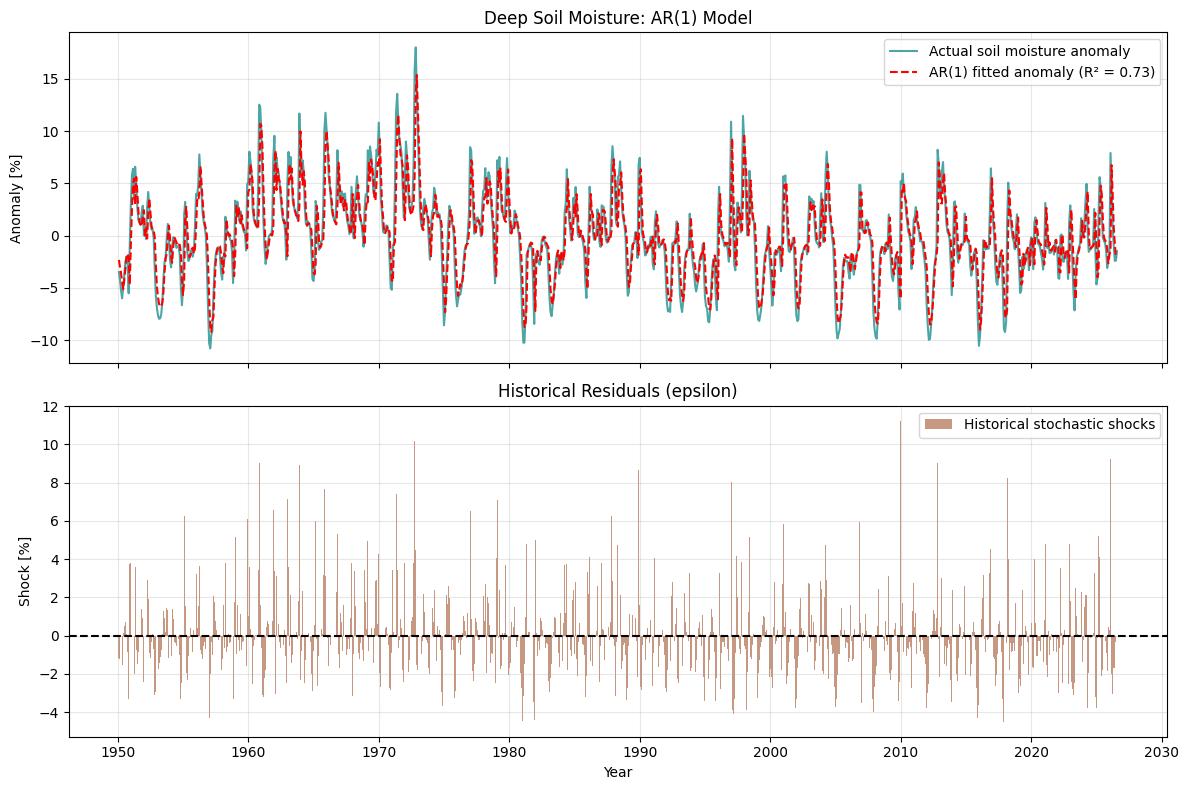


--- Stochastic Deep Soil Moisture Forecast ---
            SM_anomaly_pred  epsilon_sampled    SM_pred  SMA_pred
2026-09-01          -5.6069          -4.3448  11.802300    0.0000
2026-10-01          -6.5689          -1.7844  11.258300    0.0000
2026-11-01          -8.3346          -2.7293  12.598300    0.0000
2026-12-01          -6.8196           0.2924  18.230600    0.1272
2027-01-01          -8.0507          -2.2314  20.871500    0.2332
2027-02-01          -9.6098          -2.7401  21.367201    0.2530
2027-03-01          -8.7612          -0.5610  22.498800    0.2985
2027-04-01          -9.2570          -1.7810  20.723700    0.2272
2027-05-01          -7.8979           0.0012  19.859100    0.1925
2027-06-01          -7.7311          -0.9917  16.646200    0.0636
2027-07-01          -7.1350          -0.5380  13.626100    0.0000
2027-08-01          -5.9405           0.1479  12.369400    0.0000


In [20]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# ============================================================
# 1. RETRIEVE AND PREPARE DEEP SOIL MOISTURE DATA
# ============================================================

# Folder containing the NetCDF file and filename
folder = r'C:\MAT3300'
sm_file = os.path.join(folder, 'fin.nc')

# Open the dataset
ds_sm = xr.open_dataset(sm_file)

# Pull deep soil moisture ("swvl3") for our date range, average across all
# lat/lon grid cells into one regional series and group into monthly averages ("1MS")
sm_time_series = (
    ds_sm["swvl3"]
    .sel(valid_time=slice("1950-01-01", "2026-08-31"))
    .mean(dim=["latitude", "longitude"], skipna=True)
    .resample(valid_time="1MS")
    .mean()
*100
)

# Put the series into a DataFrame with dates as the index and drop empty rows
df = pd.DataFrame(
    {'SM': sm_time_series.values},
    index=pd.DatetimeIndex(sm_time_series.valid_time.values)
).dropna()

# Sort chronologically and record which calendar month (1-12) each row belongs to
df = df.sort_index()
df['month'] = df.index.month

# Average soil moisture for each calendar month across the whole record (seasonal baseline)
monthly_means = df.groupby('month')['SM'].mean()

# Subtract each month's historical average so we see how wet or dry a month is
# relative to a typical month of that same name (the anomaly)
df_full = df.copy()

df_full['SM_anomaly'] = (
    df_full['SM'] - df_full['month'].map(monthly_means)
)

# Shift anomalies down by one row so each row holds the anomaly from the month before
df_full['SM_lag1'] = df_full['SM_anomaly'].shift(1)

# Remove the first row since there is no prior month before the start of our data
df_model = df_full.dropna().copy()

# Input: previous month's anomaly | Target: current month's anomaly
X_full = df_model[['SM_lag1']]
y_full = df_model['SM_anomaly']

# Fit a line through the origin: current_anomaly = phi * previous_anomaly
reg = LinearRegression(fit_intercept=False)
reg.fit(X_full, y_full)

# How much of last month's anomaly carries over into this month (soil memory)
phi = reg.coef_[0]

# Anomaly predicted purely from last month's memory
df_model['SM_pred'] = reg.predict(X_full)

# Leftover each month: actual anomaly minus what memory alone predicted, this counts as a historical error
df_model['noise_epsilon'] = (
    df_model['SM_anomaly'] - df_model['SM_pred']
)

# Array of historical errors we can randomly sample from in future months
residuals = df_model['noise_epsilon'].to_numpy()

# metrics of error
r2 = reg.score(X_full, y_full)

rmse = np.sqrt(
    np.mean(df_model['noise_epsilon'] ** 2)
)

print("\n--- Final Stochastic AR(1) Model ---")
print(f"Soil memory coefficient (phi): {phi:.4f}")
print(f"R²: {r2:.4f}")
print(f"RMSE: {rmse:.4f}%")
print(
    "Residual standard deviation: "
    f"{df_model['noise_epsilon'].std():.4f}%"
)


# ============================================================
# 4. PLOT HISTORICAL MODEL FIT AND STOCHASTIC ERRORS
# ============================================================

# Top panel: actual anomalies vs. memory-only predictions
# Bottom panel: monthly errors (residuals) over time
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

ax1.plot(
    df_model.index,
    df_model['SM_anomaly'],
    label="Actual soil moisture anomaly",
    color="teal",
    alpha=0.7
)

ax1.plot(
    df_model.index,
    df_model['SM_pred'],
    label=f"AR(1) fitted anomaly (R² = {r2:.2f})",
    color="red",
    linestyle="--"
)

ax1.set_ylabel("Anomaly [%]")
ax1.set_title("Deep Soil Moisture: AR(1) Model")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.bar(
    df_model.index,
    df_model['noise_epsilon'],
    width=25,
    color="sienna",
    alpha=0.6,
    label="Historical stochastic shocks"
)

ax2.axhline(0, color="black", linestyle="--")
ax2.set_ylabel("Shock [%]")
ax2.set_xlabel("Year")
ax2.set_title("Historical Residuals (epsilon)")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 5. GENERATE STOCHASTIC FUTURE SOIL MOISTURE FORECAST
# ============================================================

# How many months ahead to simulate (can be increased for longer runs)
forecast_horizon = 12  # Number of months to forecast subject to change, we will change this in future

# Fixed random seed so one run can be reproduced reliably
rng = np.random.default_rng(seed=42)

# Historical min and max used to rescale soil moisture onto a 0-to-1 availability scale
SM_min = df['SM'].min()
SM_max = df['SM'].max()

# Start the rollout using the most recent observed anomaly
previous_anomaly = df_full['SM_anomaly'].iloc[-1]

# Monthly dates starting the month after our last data point
forecast_dates = pd.date_range(
    start=df.index[-1] + pd.offsets.MonthBegin(1),
    periods=forecast_horizon,
    freq='MS'
)

# Lists to collect each month's simulated values
predicted_anomalies = []
predicted_SM = []
predicted_SMA = []
sampled_errors = []

# Roll forward one month at a time
for date in forecast_dates:

    month = date.month

    # Pick one random surprise from past data (with replacement)
    epsilon_next = rng.choice(residuals)# we can change the noise

    # Next anomaly = carried-over memory from last month + this month's random surprise
    anomaly_next = phi * previous_anomaly + epsilon_next

    # Turn the anomaly back into soil moisture by adding that month's historical average
    SM_next = monthly_means.loc[month] + anomaly_next

    # Rescale to [0, 1] relative water availability and cap values at 0 and 1
    SMA_next = np.clip(
        (SM_next - SM_min) / (SM_max - SM_min),
        0,
        1
    )

    # Save this month's results
    predicted_anomalies.append(anomaly_next)
    predicted_SM.append(SM_next)
    predicted_SMA.append(SMA_next)
    sampled_errors.append(epsilon_next)

    # This month's anomaly becomes the "previous month's anomaly" for the next step
    previous_anomaly = anomaly_next


# Combine simulated months into a forecast table(to check validity compared to standard ecological observations)
df_forecast = pd.DataFrame(
    {
        'SM_anomaly_pred': predicted_anomalies,
        'epsilon_sampled': sampled_errors,
        'SM_pred': predicted_SM,
        'SMA_pred': predicted_SMA
    },
    index=forecast_dates
)

print("\n--- Stochastic Deep Soil Moisture Forecast ---")
print(df_forecast.round(4))


# ============================================================
# 6. CONSTRUCT THE CONTINUOUS SMA FUNCTION
# ============================================================

# Water availability at t = 0 (the last observed month in our dataset)
last_observed_SMA = np.clip(
    (df['SM'].iloc[-1] - SM_min) / (SM_max - SM_min),
    0,
    1
)

# Put the last observed date first, followed by all forecast dates
interpolation_dates = (
    pd.DatetimeIndex([df.index[-1]])
    .append(forecast_dates)
)

# Pair those dates with their corresponding [0, 1] availability values
interpolation_values = np.concatenate(
    (
        [last_observed_SMA],
        df_forecast['SMA_pred'].to_numpy()
    )
)

# Express each point as days elapsed since t = 0 (df.index[-1])
t_days = (
    interpolation_dates - df.index[-1]
).days.to_numpy()


The above results are reasonable if we compare them to standard weather cycle phenomena in the mediteranean region. Below we have the formulation of the shallow water.

I would like to turn your attention to this command(line 184 in the above cell): epsilon_next = rng.choice(residuals) we can change the noise$ in the above code. This command chooses a randomly sampled residual. When we are actually going to implement the model this noise will change to account for the different scenarios our problem asks us to do.



--- Final Stochastic Shallow Model ---
phi (SM_lag1): 0.4276 | beta_PET: -2511.3860
R²: 0.5360 | RMSE: 3.0890% | Noise std: 3.0907%


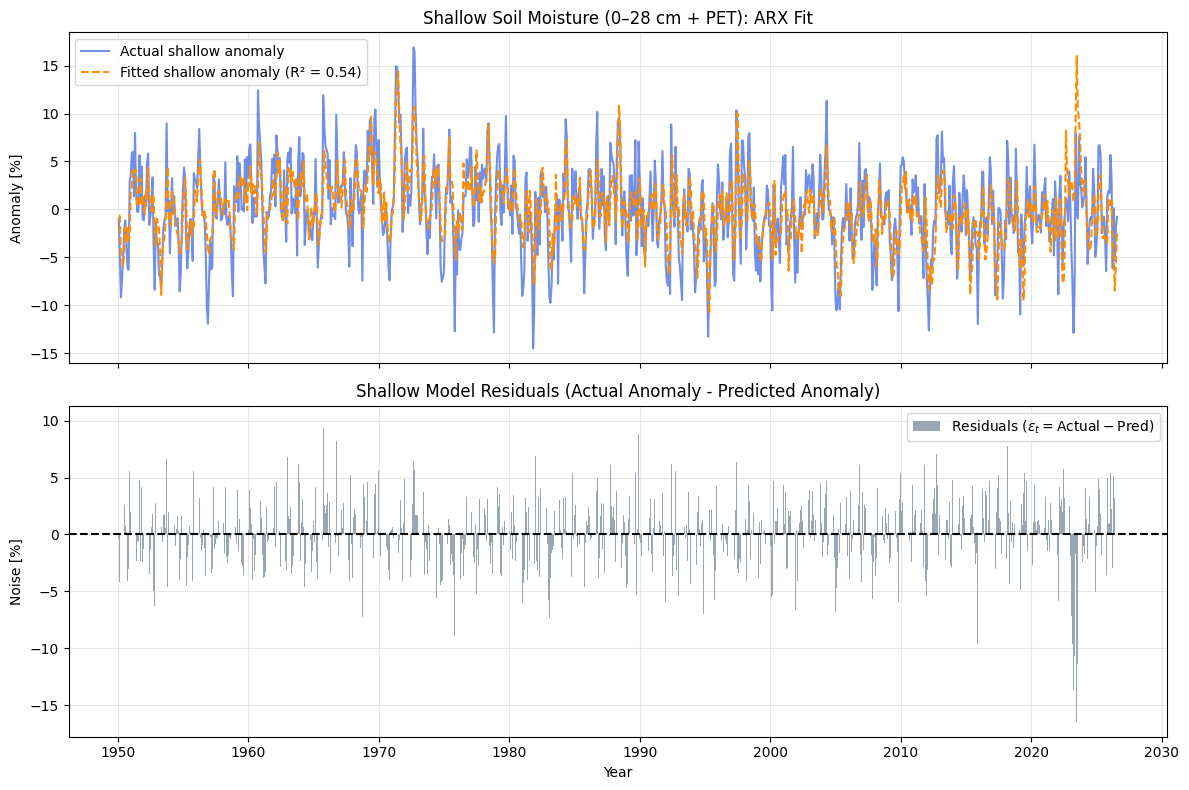


--- Stochastic Shallow Soil Moisture Forecast (with Month-Matched PET) ---
            PET_anomaly_sampled  SM_anomaly_pred  epsilon_sampled    SM_pred  \
2026-09-01               0.0000          -1.0279          -0.6261  15.605000   
2026-10-01              -0.0002           3.5588           3.4763  25.784100   
2026-11-01              -0.0001           0.1078          -1.5966  29.226200   
2026-12-01              -0.0002          -0.1673          -0.5944  31.993200   
2027-01-01               0.0000          -3.2027          -3.0385  30.397699   
2027-02-01               0.0001           2.5725           4.1618  36.166901   
2027-03-01               0.0001          -1.1207          -2.0000  30.508400   
2027-04-01               0.0017          -3.3207           1.3958  26.176901   
2027-05-01              -0.0001          -2.3125          -1.1405  23.242500   
2027-06-01               0.0013          -5.4866          -1.3523  14.840400   
2027-07-01              -0.0017           2.

In [ ]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# ============================================================
# 1. RETRIEVE AND PREPARE SHALLOW SOIL MOISTURE & PET DATA
# ============================================================

# Folder and NetCDF filename containing shallow soil layers and potential evaporation
folder = r'C:\MAT3300'
shallow_file = os.path.join(folder, 'fin.nc')      # Contains 0-7cm and 7-28cm layers

# Open the NetCDF dataset
ds_shallow = xr.open_dataset(shallow_file)

# Thickness-weighted average of 0-7 cm ("swvl1", 7 cm) and 7-28 cm ("swvl2", 21 cm)
# across the full 0-28 cm shallow zone, spatially averaged over lat/lon and grouped by month
shallow_sm_ts = (
    ((7*ds_shallow["swvl1"] + 21*ds_shallow["swvl2"])/28)
    .sel(valid_time=slice("1950-01-01", "2026-08-31"))
    .mean(dim=["latitude", "longitude"], skipna=True)
    .resample(valid_time="1MS")
    .mean()
*100  # convert volumetric fraction to %
)

# Flip sign of potential evaporation ("pev") because in the dataset it is stored as negative
pet_ts = (
    -ds_shallow["pev"]
    .sel(valid_time=slice("1950-01-01", "2026-08-31"))
    .mean(dim=["latitude", "longitude"], skipna=True)
    .resample(valid_time="1MS")
    .mean()
)

# Combine shallow soil moisture ("SM") and potential evaporation ("PET") into one table
# indexed by date, and drop any rows with missing values
df_s = pd.DataFrame(
    {
        "SM": shallow_sm_ts.values,
        "PET": pet_ts.values,
    },
    index=pd.DatetimeIndex(shallow_sm_ts.valid_time.values),
).dropna()

# Sort chronologically and record calendar month (1-12) for each row
df_s = df_s.sort_index()
df_s["month"] = df_s.index.month


features = ["SM_lag1", "PET_anomaly"]

# Compute full-record monthly averages for SM and PET across all available years
monthly_means_s = df_s.groupby("month")["SM"].mean()
monthly_means_pet = df_s.groupby("month")["PET"].mean()

# Calculate anomalies relative to the full-record seasonal averages
df_s_full = df_s.copy()
df_s_full["SM_anomaly"] = df_s_full["SM"] - df_s_full["month"].map(monthly_means_s)
df_s_full["PET_anomaly"] = df_s_full["PET"] - df_s_full["month"].map(monthly_means_pet)

# Store the previous month's shallow anomaly on each row for memory persistence
df_s_full["SM_lag1"] = df_s_full["SM_anomaly"].shift(1)

# Remove the initial row where the previous month is missing
df_s_model = df_s_full.dropna().copy()

X_s_full = df_s_model[features]
y_s_full = df_s_model["SM_anomaly"]

# Fit the final shallow model across the entire dataset
reg_s = LinearRegression(fit_intercept=False)
reg_s.fit(X_s_full, y_s_full)

# phi_s: memory carried over from previous month's shallow anomaly
# beta_pet: sensitivity of shallow soil moisture anomaly to PET anomaly
phi_s = reg_s.coef_[0]
beta_pet = reg_s.coef_[1]

# Anomaly predicted by previous-month memory + PET anomaly
df_s_model["SM_anomaly_pred"] = reg_s.predict(X_s_full)

# Leftover surprise each month: actual anomaly minus model-predicted anomaly
df_s_model["noise_epsilon"] = df_s_model["SM_anomaly"] - df_s_model["SM_anomaly_pred"]
residuals_s = df_s_model["noise_epsilon"].to_numpy()

# Overall fit and residual error size
r2_s = reg_s.score(X_s_full, y_s_full)
rmse_s = np.sqrt(np.mean(df_s_model["noise_epsilon"] ** 2))

print("\n--- Final Stochastic Shallow Model ---")
print(f"phi (SM_lag1): {phi_s:.4f} | beta_PET: {beta_pet:.4f}")
print(f"R²: {r2_s:.4f} | RMSE: {rmse_s:.4f}% | Noise std: {df_s_model['noise_epsilon'].std():.4f}%")

# Top panel: actual vs. predicted shallow anomalies
# Bottom panel: monthly surprises (residuals) over time
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.plot(df_s_model.index, df_s_model["SM_anomaly"], label="Actual shallow anomaly", color="royalblue", alpha=0.75)
ax1.plot(df_s_model.index, df_s_model["SM_anomaly_pred"], label=f"Fitted shallow anomaly (R² = {r2_s:.2f})", color="darkorange", linestyle="--")
ax1.set_ylabel("Anomaly [%]")
ax1.set_title("Shallow Soil Moisture (0–28 cm + PET): ARX Fit")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.bar(df_s_model.index, df_s_model["noise_epsilon"], width=20, color="slategray", alpha=0.7, label=r"Residuals ($\varepsilon_t = \text{Actual} - \text{Pred}$)")
ax2.axhline(0, color="black", linestyle="--")
ax2.set_ylabel("Noise [%]")
ax2.set_xlabel("Year")
ax2.set_title("Shallow Model Residuals (Actual Anomaly - Predicted Anomaly)")
ax2.legend()
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 4. STOCHASTIC SHALLOW FORECAST & CONTINUOUS W_shallow(t)
# ============================================================

# Group historical PET anomalies by calendar month (1-12) so future draws match
# the seasonal evaporative behavior of each forecast month
pet_anom_by_month = {
    m: grp["PET_anomaly"].to_numpy()
    for m, grp in df_s_full.groupby("month")
}

# Number of months to simulate ahead
forecast_horizon = 12

# Fixed random seed for reproducible single-realization testing
rng_s = np.random.default_rng(seed=42)

# Historical min and max used to rescale shallow soil moisture onto [0, 1]
SM_min_s = df_s["SM"].min()
SM_max_s = df_s["SM"].max()

# Initialize rollout with the most recent observed shallow anomaly
previous_anomaly_s = df_s_full["SM_anomaly"].iloc[-1]

# Monthly timestamps starting the month after our last observation
forecast_dates_s = pd.date_range(
    start=df_s.index[-1] + pd.offsets.MonthBegin(1),
    periods=forecast_horizon,
    freq="MS",
)

# Containers to record each month's simulated PET anomaly, anomaly, SM, SMA, and shock
pred_anomalies_s = []
pred_pet_anom_s = []
pred_sm_s = []
pred_sma_s = []
sampled_eps_s = []

# Roll forward one month at a time
for date in forecast_dates_s:
    month = date.month

    # Draw a historical PET anomaly from the same calendar month
    pet_anom_next = float(rng_s.choice(pet_anom_by_month[month]))

    # Draw one historical surprise (actual anomaly minus predicted anomaly) with replacement
    eps_next = float(rng_s.choice(residuals_s))

    # Next anomaly = memory from previous month + PET effect + sampled surprise
    anomaly_next_s = phi_s * previous_anomaly_s + beta_pet * pet_anom_next + eps_next

    # Reconstruct shallow soil moisture by adding this month's historical mean
    sm_next_s = monthly_means_s.loc[month] + anomaly_next_s

    # Rescale to [0, 1] relative water availability and clamp out-of-range values
    sma_next_s = np.clip((sm_next_s - SM_min_s) / (SM_max_s - SM_min_s), 0.0, 1.0)

    # Save monthly outputs
    pred_anomalies_s.append(anomaly_next_s)
    pred_pet_anom_s.append(pet_anom_next)
    pred_sm_s.append(sm_next_s)
    pred_sma_s.append(sma_next_s)
    sampled_eps_s.append(eps_next)

    # Carry forward current anomaly as the previous month's anomaly for the next step
    previous_anomaly_s = anomaly_next_s

# Store monthly forecast results in a DataFrame
df_forecast_s = pd.DataFrame(
    {
        "PET_anomaly_sampled": pred_pet_anom_s,
        "SM_anomaly_pred": pred_anomalies_s,
        "epsilon_sampled": sampled_eps_s,
        "SM_pred": pred_sm_s,
        "SMA_pred": pred_sma_s,
    },
    index=forecast_dates_s,
)

print("\n--- Stochastic Shallow Soil Moisture Forecast (with Month-Matched PET) ---")
print(df_forecast_s.round(4))

# Shallow water availability at t = 0 (last observed month)
last_obs_sma_s = np.clip((df_s["SM"].iloc[-1] - SM_min_s) / (SM_max_s - SM_min_s), 0.0, 1.0)

# Prepend last observed timestamp and convert dates to days elapsed since t = 0
interp_dates_s = pd.DatetimeIndex([df_s.index[-1]]).append(forecast_dates_s)
interp_vals_s = np.concatenate(([last_obs_sma_s], df_forecast_s["SMA_pred"].to_numpy()))
t_days_s = (interp_dates_s - df_s.index[-1]).days.to_numpy(dtype=float)



We now convert them into continuous functions using cubic spline. Since we will use the water moisture functions for a differential equation we will need them to be sufficiently smooth. We also check whether linear interpolation is better.


Deep Water Cubic Spline vs. W_deep(t) RMSE: 0.0058


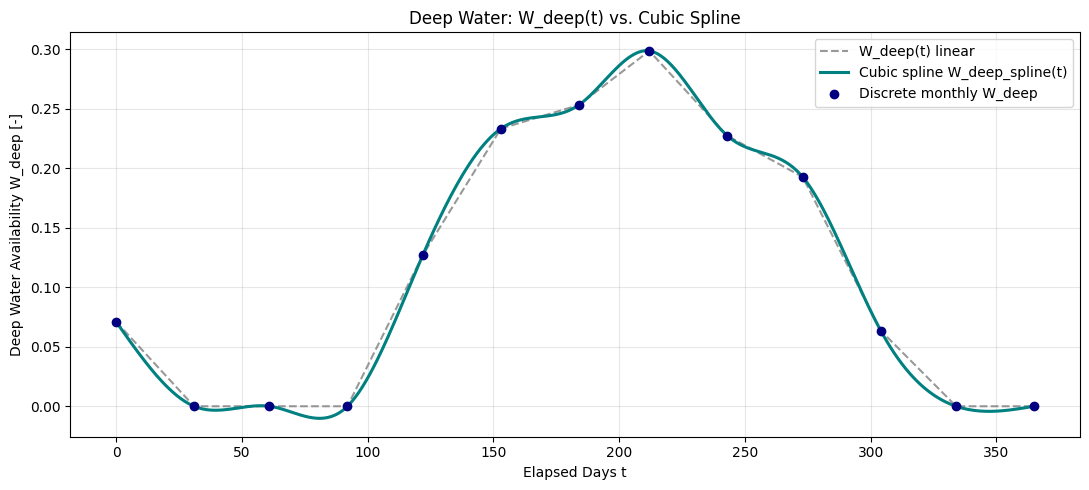

Shallow Water Cubic Spline vs. W_shallow(t) RMSE: 0.0187


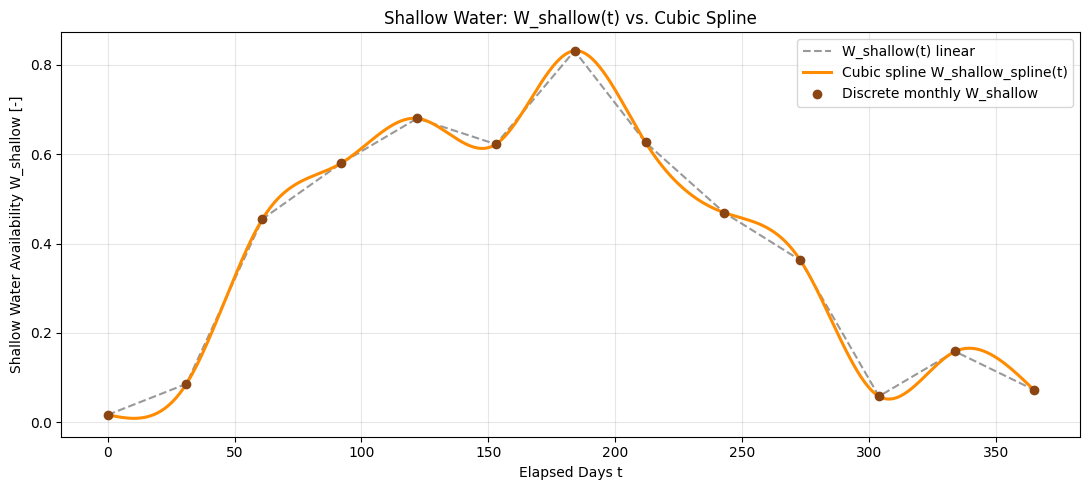

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from sklearn.metrics import mean_squared_error

# ============================================================
# 1. DEEP WATER: W_deep(t) AND CUBIC SPLINE
# ============================================================

t_nodes_d = np.asarray(t_days, dtype=float)
w_nodes_d = np.asarray(interpolation_values, dtype=float)


def W_deep(t):
  """Piecewise-linear deep water availability function W_deep(t) at elapsed days t."""
  t_arr = np.asarray(t, dtype=float)
  return np.interp(np.clip(t_arr, t_nodes_d[0], t_nodes_d[-1]), t_nodes_d, w_nodes_d)


# Fit cubic spline directly from W_deep evaluated at the node timestamps
cs_deep = CubicSpline(t_nodes_d, W_deep(t_nodes_d), bc_type="natural")


def W_deep_spline(t):
  """Smooth cubic spline built from W_deep(t)."""
  t_arr = np.asarray(t, dtype=float)
  return cs_deep(np.clip(t_arr, t_nodes_d[0], t_nodes_d[-1]))


# Compare cubic spline against W_deep(t) on a fine time grid
t_fine_d = np.linspace(t_nodes_d[0], t_nodes_d[-1], 500)
w_linear_fine_d = W_deep(t_fine_d)
w_spline_fine_d = W_deep_spline(t_fine_d)

rmse_deep = np.sqrt(mean_squared_error(w_linear_fine_d, w_spline_fine_d))
print(f"Deep Water Cubic Spline vs. W_deep(t) RMSE: {rmse_deep:.4f}")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(t_fine_d, w_linear_fine_d, linestyle="--", color="gray", alpha=0.8, label="W_deep(t) linear")
ax.plot(t_fine_d, w_spline_fine_d, color="teal", linewidth=2.2, label="Cubic spline W_deep_spline(t)")
ax.scatter(t_nodes_d, W_deep(t_nodes_d), color="navy", zorder=5, label="Discrete monthly W_deep")
ax.set_xlabel("Elapsed Days t")
ax.set_ylabel("Deep Water Availability W_deep [-]")
ax.set_title("Deep Water: W_deep(t) vs. Cubic Spline")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 2. SHALLOW WATER: W_shallow(t) AND CUBIC SPLINE
# ============================================================

t_nodes_s = np.asarray(t_days_s, dtype=float)
w_nodes_s = np.asarray(interp_vals_s, dtype=float)


def W_shallow(t):
  """Piecewise-linear shallow water availability function W_shallow(t) at elapsed days t."""
  t_arr = np.asarray(t, dtype=float)
  return np.interp(np.clip(t_arr, t_nodes_s[0], t_nodes_s[-1]), t_nodes_s, w_nodes_s)


# Fit cubic spline directly from W_shallow evaluated at the node timestamps
cs_shallow = CubicSpline(t_nodes_s, W_shallow(t_nodes_s), bc_type="natural")


def W_shallow_spline(t):
  """Smooth cubic spline built from W_shallow(t)."""
  t_arr = np.asarray(t, dtype=float)
  return cs_shallow(np.clip(t_arr, t_nodes_s[0], t_nodes_s[-1]))


# Compare cubic spline against W_shallow(t) on a fine time grid
t_fine_s = np.linspace(t_nodes_s[0], t_nodes_s[-1], 500)
w_linear_fine_s = W_shallow(t_fine_s)
w_spline_fine_s = W_shallow_spline(t_fine_s)

rmse_shallow = np.sqrt(mean_squared_error(w_linear_fine_s, w_spline_fine_s))
print(f"Shallow Water Cubic Spline vs. W_shallow(t) RMSE: {rmse_shallow:.4f}")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(t_fine_s, w_linear_fine_s, linestyle="--", color="gray", alpha=0.8, label="W_shallow(t) linear")
ax.plot(t_fine_s, w_spline_fine_s, color="darkorange", linewidth=2.2, label="Cubic spline W_shallow_spline(t)")
ax.scatter(t_nodes_s, W_shallow(t_nodes_s), color="saddlebrown", zorder=5, label="Discrete monthly W_shallow")
ax.set_xlabel("Elapsed Days t")
ax.set_ylabel("Shallow Water Availability W_shallow [-]")
ax.set_title("Shallow Water: W_shallow(t) vs. Cubic Spline")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The above results are reasonable because the interpolation happens from the next last observed month in the dataset, which is August. The formula follows standard precipitation and water patterns occuring in mediterenean countries. It is also representative of the idea that more shallow water eventually passes in the deeper grounds, which is why for example the bumb in the shallow water between days 150-200, occurs later in the deeper water function.

This is the final formulation. \Omega needs to be found or estimated from the spieces behavior. Omega closer to 1 implies the spieces reach for shallow water whereas omega closer to zero implies the spieces reach for deeper water. In case the interpolation results in a value smaller than 0 then we add a small positive floor to make the function smooth without altering its values significantly.


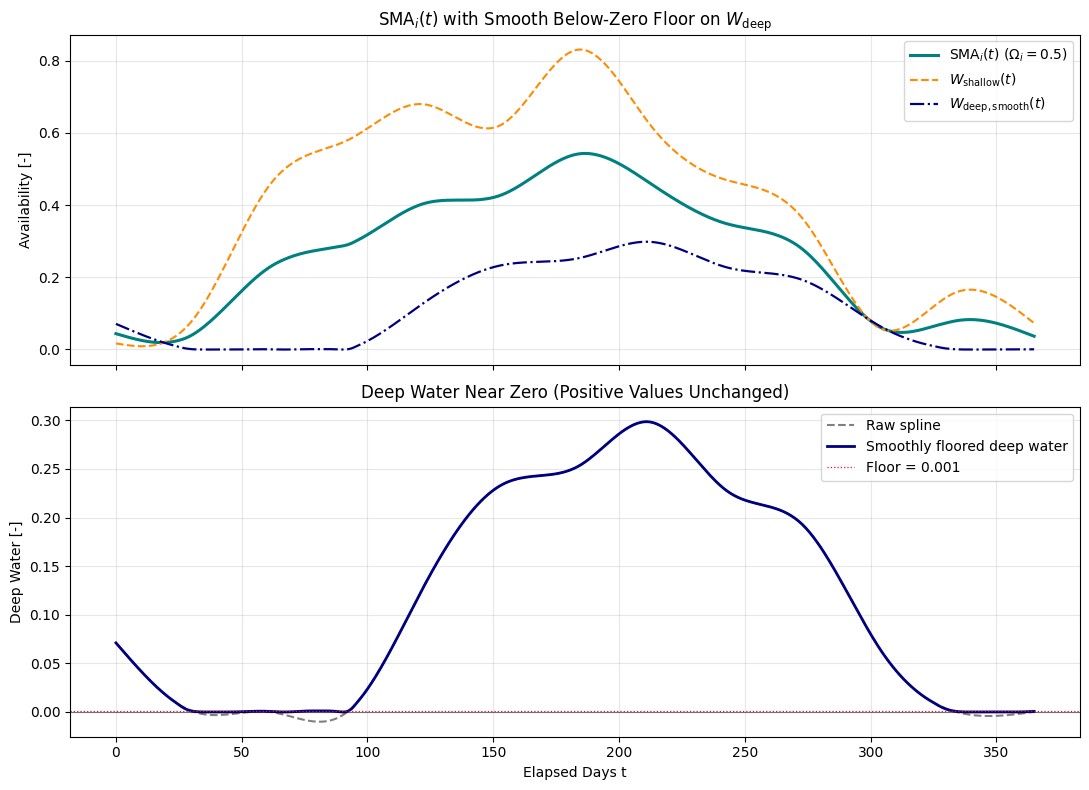

In [34]:
import matplotlib.pyplot as plt
import numpy as np

omega_i = 0.5
eps_deep = 1e-3  # small positive floor when below 0
half_width = 0.01  # smoothing half-band around 0 (in SMA units)


def smooth_below_zero_floor(x, floor=1e-3, half_width=0.02):
  """Leaves x > half_width untouched; smoothly lifts x < 0 to `floor` near 0."""
  x_arr = np.asarray(x, dtype=float)
  # Weight w = 0 for x <= -half_width (floor), w = 1 for x >= +half_width (raw x)
  u = np.clip((x_arr + half_width) / (2.0 * half_width), 0.0, 1.0)
  blend = u * u * (3.0 - 2.0 * u)  # C1-smoothstep on [0, 1]
  return (1.0 - blend) * floor + blend * x_arr


def W_deep_smooth_floor(t):
  return smooth_below_zero_floor(
      W_deep_spline(t), floor=eps_deep, half_width=half_width
  )

#the function#
def SMA_i(t):
  w_shallow = W_shallow_spline(t)
  w_deep = W_deep_smooth_floor(t)
  return omega_i * w_shallow + (1.0 - omega_i) * w_deep


# Plot comparison around 0 and across the full time grid
t_min = min(float(t_nodes_d[0]), float(t_nodes_s[0]))
t_max = max(float(t_nodes_d[-1]), float(t_nodes_s[-1]))
t_grid = np.linspace(t_min, t_max, 500)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

ax1.plot(
    t_grid,
    SMA_i(t_grid),
    color="teal",
    lw=2.2,
    label=rf"$\mathrm{{SMA}}_i(t)$ ($\Omega_i = {omega_i}$)",
)
ax1.plot(
    t_grid,
    W_shallow_spline(t_grid),
    color="darkorange",
    lw=1.5,
    ls="--",
    label=r"$W_{\mathrm{shallow}}(t)$",
)
ax1.plot(
    t_grid,
    W_deep_smooth_floor(t_grid),
    color="navy",
    lw=1.6,
    ls="-.",
    label=r"$W_{\mathrm{deep, smooth}}(t)$",
)
ax1.set_ylabel("Availability [-]")
ax1.set_title(r"$\mathrm{SMA}_i(t)$ with Smooth Below-Zero Floor on $W_{\mathrm{deep}}$")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(
    t_grid,
    W_deep_spline(t_grid),
    color="gray",
    lw=1.5,
    ls="--",
    label="Raw spline",
)
ax2.plot(
    t_grid,
    W_deep_smooth_floor(t_grid),
    color="navy",
    lw=2.0,
    label="Smoothly floored deep water",
)
ax2.axhline(0.0, color="black", lw=0.8, alpha=0.5)
ax2.axhline(eps_deep, color="crimson", lw=0.9, ls=":", label=f"Floor = {eps_deep}")
ax2.set_xlabel("Elapsed Days t")
ax2.set_ylabel("Deep Water [-]")
ax2.set_title("Deep Water Near Zero (Positive Values Unchanged)")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Something that should be noted is that the stochastic models are generated using different errors, which since we are modelling irregular drought cycles, should not be a problem.


In [ ]:
#the function#
def SMA_i(t):
  w_shallow = W_shallow_spline(t)
  w_deep = W_deep_smooth_floor(t)
  return omega_i * w_shallow + (1.0 - omega_i) * w_deep
